# Notebook 09 — Abnormal-Condition Stress Test

## Objective
Investigate how forecasting performance changes when traffic inputs are subjected to controlled synthetic speed-reduction perturbations.

## Experimental Idea
Compare predictions under normal inputs with predictions under progressively stronger synthetic perturbations.

## Metrics
- MAE
- RMSE
- MAPE
- Relative metric changes compared with the unperturbed condition

## Previously Recorded Reconstructed Run

Normal condition:
- MAE: 6.4373
- RMSE: 11.3119
- MAPE: 14.0925%

At 30% perturbation:
- MAE increased by approximately 7.92%.
- RMSE increased by approximately 1.87%.
- MAPE increased by approximately 3.47%.

These figures belong to one reconstructed run and must be verified against the final notebook before being reported as final results.

## Interpretation
The experiment measures model sensitivity to the selected synthetic perturbation. In the recorded run, MAE increased as perturbation strength increased.

This does not establish robustness to all real-world incidents, accidents, missing sensor data, or distribution shifts.

## Limitations
- The perturbations are synthetic.
- Real incidents can differ substantially from the chosen perturbation procedure.
- Findings depend on the model checkpoint and evaluation protocol.

## Review Reminder
Be prepared to explain:
- Why stress testing is useful.
- How the synthetic perturbation was applied in the actual notebook.
- How performance changed with perturbation strength.
- Why synthetic testing is not equivalent to evaluation on real incidents.

# UrbanFlow AI — Notebook 09: Abnormal-Condition Stress Test

## Objective
Evaluate how the trained Multi-Scale STGCN responds when recent historical traffic observations are synthetically perturbed to represent sudden speed reductions at a subset of sensors.

**This is a synthetic stress test, not a real accident/incident simulation.** The future targets are left unchanged. Therefore, this experiment measures sensitivity to corrupted or shifted historical inputs, not the causal effect of a real incident on future traffic.

## Protocol
- Dataset: METR-LA, 207 sensors, 5-minute sampling.
- Input: 12 steps (60 minutes); forecast: 3 steps (15 minutes).
- Perturb the last 3 input steps (15 minutes) at 10% of sensors (about 21 sensors).
- Speed reduction levels: 5%, 10%, 20%, and 30%.
- Keep the selected sensor subset fixed across levels for a controlled comparison.
- Evaluate predictions in the original speed scale against the unchanged test targets.
- Use the already-trained combined-kernel checkpoint; do not retrain on perturbed test data.


In [40]:
from pathlib import Path
import json, pickle, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
INPUT_STEPS = 12
OUTPUT_STEPS = 3
NUM_NODES = 207
HIDDEN_CHANNELS = 32
DROPOUT = 0.2
BATCH_SIZE = 64
AFFECTED_SENSOR_FRACTION = 0.10
PERTURB_LAST_STEPS = 3
SPEED_DROP_LEVELS = [0.05, 0.10, 0.20, 0.30]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    print("Drive mount skipped (not running in Google Colab).")

PROJECT_ROOT = Path("/content/drive/MyDrive/urbanAi")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "METR-LA"
CHECKPOINT_PATH = Path("/content/experiments/multiscale_ablation/kernels_3_5/best_model.pt")
OUTPUT_DIR = Path("/content/experiments/robustness_stress_test")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert (PROCESSED_DIR / "train.npz").exists(), f"Missing processed data: {PROCESSED_DIR}"
assert (PROCESSED_DIR / "test.npz").exists(), f"Missing test split in {PROCESSED_DIR}"
assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}\n"
    "Run the combined-kernel experiment in Notebook 06 first, or update CHECKPOINT_PATH "
    "to the checkpoint you intend to evaluate."
)
print("Processed data:", PROCESSED_DIR)
print("Checkpoint:", CHECKPOINT_PATH)
print("Output directory:", OUTPUT_DIR)


Device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processed data: /content/drive/MyDrive/urbanAi/data/processed/METR-LA
Checkpoint: /content/experiments/multiscale_ablation/kernels_3_5/best_model.pt
Output directory: /content/experiments/robustness_stress_test


## 1. Load test data, adjacency matrix, and training-fitted scaler

In [41]:
def load_split(path):
    with np.load(path) as d:
        X = d["X"].astype(np.float32)
        Y = d["Y"].astype(np.float32)
    assert X.ndim == 4 and tuple(X.shape[1:]) == (INPUT_STEPS, NUM_NODES, 1), X.shape
    assert Y.ndim == 4 and tuple(Y.shape[1:]) == (OUTPUT_STEPS, NUM_NODES, 1), Y.shape
    assert len(X) == len(Y)
    assert np.isfinite(X).all() and np.isfinite(Y).all()
    return X, Y

X_test_scaled, Y_test_scaled = load_split(PROCESSED_DIR / "test.npz")
print("Test X:", X_test_scaled.shape, "| Test Y:", Y_test_scaled.shape)

adj_path = PROCESSED_DIR / "adj_METR-LA.pkl"
assert adj_path.exists(), f"Adjacency file not found: {adj_path}"
with open(adj_path, "rb") as f:
    adj_data = pickle.load(f, encoding="latin1")
adj_np = np.asarray(adj_data[-1] if isinstance(adj_data, (tuple, list)) else adj_data, dtype=np.float32)
assert adj_np.shape == (NUM_NODES, NUM_NODES), adj_np.shape
degree = adj_np.sum(axis=1)
assert np.all(degree > 0), "At least one adjacency row has zero degree."
adj_np = adj_np / degree[:, None]
assert np.allclose(adj_np.sum(axis=1), 1.0, atol=1e-5)
A = torch.tensor(adj_np, dtype=torch.float32, device=DEVICE)

scaler_path = PROCESSED_DIR / "scaler.npz"
assert scaler_path.exists(), f"Scaler not found: {scaler_path}"
with np.load(scaler_path) as s:
    scaler_mean = s["mean"].astype(np.float32).reshape(-1)
    scaler_std = s["std"].astype(np.float32).reshape(-1)
assert scaler_mean.shape == (NUM_NODES,) and scaler_std.shape == (NUM_NODES,)
assert np.all(scaler_std > 0)

mean_np = scaler_mean.reshape(1, 1, NUM_NODES, 1)
std_np = scaler_std.reshape(1, 1, NUM_NODES, 1)

def inverse_scale(x):
    return x * std_np + mean_np

def scale_original(x):
    return (x - mean_np) / std_np

Y_test_original = inverse_scale(Y_test_scaled).astype(np.float32)
print("Adjacency and scaler loaded.")
print("Target original-scale shape:", Y_test_original.shape)


Test X: (6841, 12, 207, 1) | Test Y: (6841, 3, 207, 1)
Adjacency and scaler loaded.
Target original-scale shape: (6841, 3, 207, 1)


## 2. Define the same model architecture used in Notebook 06

In [42]:
class MultiScaleTemporalConv(nn.Module):
    def __init__(self,in_channels,out_channels,kernels=(3,5),dropout=0.2):
        super().__init__()
        self.branches=nn.ModuleList([nn.Conv2d(in_channels,out_channels,kernel_size=(1,k),padding=(0,k//2)) for k in kernels])
        self.fusion=nn.Conv2d(out_channels*len(kernels),out_channels,kernel_size=1)
        self.activation=nn.ReLU(); self.dropout=nn.Dropout(dropout)
    def forward(self,x):
        x=x.permute(0,3,2,1)  # B,C,N,T
        x=torch.cat([branch(x) for branch in self.branches],dim=1)
        x=self.dropout(self.activation(self.fusion(x)))
        return x.permute(0,3,2,1)  # B,T,N,C

class GraphConvolution(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__(); self.linear=nn.Linear(in_channels,out_channels)
    def forward(self,x,adjacency):
        return self.linear(torch.einsum("nm,btmc->btnc",adjacency,x))

class MultiScaleSTGCNBlock(nn.Module):
    def __init__(self,in_channels,hidden_channels,kernels=(3,5),dropout=0.2):
        super().__init__()
        self.temporal1=MultiScaleTemporalConv(in_channels,hidden_channels,kernels,dropout)
        self.graph=GraphConvolution(hidden_channels,hidden_channels)
        self.temporal2=MultiScaleTemporalConv(hidden_channels,hidden_channels,kernels,dropout)
        self.activation=nn.ReLU()
    def forward(self,x,adjacency):
        x=self.temporal1(x)
        x=self.activation(self.graph(x,adjacency))
        return self.temporal2(x)

class MultiScaleSTGCN(nn.Module):
    def __init__(self,input_steps=12,output_steps=3,input_channels=1,hidden_channels=32,kernels=(3,5),dropout=0.2):
        super().__init__()
        self.block1=MultiScaleSTGCNBlock(input_channels,hidden_channels,kernels,dropout)
        self.block2=MultiScaleSTGCNBlock(hidden_channels,hidden_channels,kernels,dropout)
        self.temporal_head=nn.Linear(input_steps,output_steps)
        self.output_head=nn.Linear(hidden_channels,1)
    def forward(self,x,adjacency):
        x=self.block1(x,adjacency); x=self.block2(x,adjacency)
        x=x.permute(0,2,3,1)   # B,N,C,T
        x=self.temporal_head(x) # B,N,C,H
        x=x.permute(0,3,1,2)  # B,H,N,C
        return self.output_head(x)

model = MultiScaleSTGCN(
    input_steps=INPUT_STEPS,
    output_steps=OUTPUT_STEPS,
    input_channels=1,
    hidden_channels=HIDDEN_CHANNELS,
    kernels=(3, 5),
    dropout=DROPOUT
).to(DEVICE)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict, strict=True)
model.eval()
print("Combined-kernel checkpoint loaded successfully.")
if isinstance(checkpoint, dict):
    print("Checkpoint metadata:", {k: checkpoint[k] for k in checkpoint if k != "model_state_dict" and k != "state_dict"})


Combined-kernel checkpoint loaded successfully.
Checkpoint metadata: {'kernels': [3, 5], 'seed': 42, 'best_epoch': 13, 'best_validation_mse': 0.3018010774006446}


## 3. Define metrics and baseline prediction

In [43]:
def calculate_metrics(y_true, y_pred, epsilon=1e-5):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    err = y_true - y_pred
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    mask = np.abs(y_true) > epsilon
    mape = (
        np.mean(np.abs(err[mask] / y_true[mask])) * 100
        if np.any(mask) else float("nan")
    )
    return {"MAE": float(mae), "RMSE": float(rmse), "MAPE": float(mape)}

@torch.no_grad()
def predict_scaled(model, X_scaled, batch_size=BATCH_SIZE):
    model.eval()
    outputs = []
    for start in range(0, len(X_scaled), batch_size):
        xb = torch.as_tensor(
            X_scaled[start:start + batch_size],
            dtype=torch.float32,
            device=DEVICE
        )
        pred = model(xb, A)
        outputs.append(pred.detach().cpu().numpy())
    return np.concatenate(outputs, axis=0)

baseline_pred_scaled = predict_scaled(model, X_test_scaled)
assert baseline_pred_scaled.shape == Y_test_scaled.shape
baseline_pred_original = inverse_scale(baseline_pred_scaled).astype(np.float32)

baseline_metrics = calculate_metrics(Y_test_original, baseline_pred_original)
print("Baseline test metrics:", baseline_metrics)


Baseline test metrics: {'MAE': 6.437299728393555, 'RMSE': 11.311905860900879, 'MAPE': 14.092522621154785}


## 4. Choose sensors and apply controlled synthetic speed drops

We select the same sensor subset for every perturbation strength using a fixed random seed. In original units, the last three observed input steps for those sensors are multiplied by `(1 - drop_fraction)`. The perturbed values are then standardized with the **existing training scaler**. Future targets are never modified.


In [44]:
rng = np.random.default_rng(SEED)
num_affected = max(1, int(round(NUM_NODES * AFFECTED_SENSOR_FRACTION)))
affected_sensors = np.sort(rng.choice(NUM_NODES, size=num_affected, replace=False))

print(f"Affected sensors: {num_affected}/{NUM_NODES} ({num_affected / NUM_NODES:.2%})")
print("Affected sensor indices:", affected_sensors.tolist())

# Convert historical inputs to original speed scale before applying percentage changes.
X_test_original = inverse_scale(X_test_scaled).astype(np.float32)
assert X_test_original.shape == X_test_scaled.shape

def make_perturbed_inputs(drop_fraction):
    if not (0.0 <= drop_fraction < 1.0):
        raise ValueError("drop_fraction must be between 0 and 1.")
    perturbed_original = X_test_original.copy()
    # Only the last 3 time steps and selected sensors are changed.
    perturbed_original[:, -PERTURB_LAST_STEPS:, affected_sensors, :] *= (1.0 - drop_fraction)
    perturbed_scaled = scale_original(perturbed_original).astype(np.float32)
    assert perturbed_scaled.shape == X_test_scaled.shape
    assert np.isfinite(perturbed_scaled).all()
    return perturbed_scaled, perturbed_original

# Confirm that zero perturbation reproduces the original standardized inputs.
X_zero, _ = make_perturbed_inputs(0.0)
assert np.allclose(X_zero, X_test_scaled, atol=1e-5)
print("Input perturbation checks passed.")


Affected sensors: 21/207 (10.14%)
Affected sensor indices: [16, 18, 26, 39, 82, 83, 92, 103, 104, 123, 135, 144, 145, 146, 152, 158, 164, 172, 192, 193, 206]
Input perturbation checks passed.


## 5. Evaluate each stress level

In [45]:
conditions = [("Normal", 0.0)] + [
    (f"{int(level * 100)}% speed drop", level) for level in SPEED_DROP_LEVELS
]
results = []
predictions_by_condition = {"Normal": baseline_pred_original}

for label, level in conditions:
    print(f"Evaluating: {label}")
    if level == 0.0:
        pred_original = baseline_pred_original
    else:
        X_perturbed_scaled, _ = make_perturbed_inputs(level)
        pred_scaled = predict_scaled(model, X_perturbed_scaled)
        pred_original = inverse_scale(pred_scaled).astype(np.float32)

    metrics = calculate_metrics(Y_test_original, pred_original)
    row = {"condition": label, "speed_drop_fraction": float(level), **metrics}
    for metric in ("MAE", "RMSE", "MAPE"):
        base = baseline_metrics[metric]
        current = metrics[metric]
        row[f"{metric}_increase_pct"] = (
            float((current - base) / base * 100) if base != 0 else float("nan")
        )
    results.append(row)
    predictions_by_condition[label] = pred_original

results_df = pd.DataFrame(results)
display(results_df.round(6))
results_df.to_csv(OUTPUT_DIR / "robustness_stress_test_results.csv", index=False)
with open(OUTPUT_DIR / "robustness_stress_test_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved results to:", OUTPUT_DIR)


Evaluating: Normal
Evaluating: 5% speed drop
Evaluating: 10% speed drop
Evaluating: 20% speed drop
Evaluating: 30% speed drop


,condition,speed_drop_fraction,MAE,RMSE,MAPE,MAE_increase_pct,RMSE_increase_pct,MAPE_increase_pct
0,Normal,0.00,6.437300,11.311906,14.092523,0.000000,0.000000,0.000000
1,5% speed drop,0.05,6.484812,11.307482,14.084087,0.738082,-0.039110,-0.059856
2,10% speed drop,0.10,6.547879,11.312733,14.114876,1.717786,0.007309,0.158617
3,20% speed drop,0.20,6.720881,11.365384,14.277983,4.405275,0.472761,1.316018
4,30% speed drop,0.30,6.946937,11.523209,14.582020,7.916936,1.867968,3.473453


Saved results to: /content/experiments/robustness_stress_test


## 6. Horizon-wise comparison

In [46]:
horizon_rows = []
for label, level in conditions:
    pred = predictions_by_condition[label]
    for h in range(OUTPUT_STEPS):
        m = calculate_metrics(Y_test_original[:, h], pred[:, h])
        horizon_rows.append({
            "condition": label,
            "horizon_minutes": (h + 1) * 5,
            **m
        })
horizon_df = pd.DataFrame(horizon_rows)
display(horizon_df.round(6))
horizon_df.to_csv(OUTPUT_DIR / "robustness_stress_test_by_horizon.csv", index=False)


,condition,horizon_minutes,MAE,RMSE,MAPE
0,Normal,5,6.067410,10.538600,13.372686
1,Normal,10,6.418780,11.337696,14.069679
2,Normal,15,6.825719,12.011343,14.835198
3,5% speed drop,5,6.111538,10.534878,13.354702
4,5% speed drop,10,6.464014,11.331913,14.057848
5,5% speed drop,15,6.878893,12.007565,14.839723
6,10% speed drop,5,6.172728,10.543004,13.379828
7,10% speed drop,10,6.524725,11.335351,14.085056
8,10% speed drop,15,6.946187,12.012028,14.879756
9,20% speed drop,5,6.346817,10.609890,13.542421


## 7. Visualize degradation

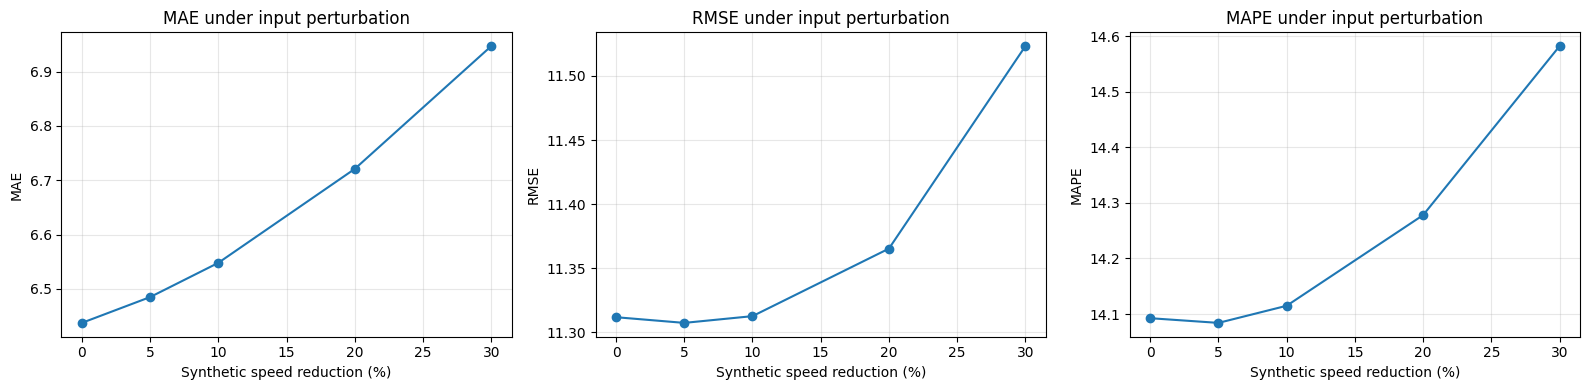

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "MAPE"]):
    ax.plot(results_df["speed_drop_fraction"] * 100, results_df[metric], marker="o")
    ax.set_xlabel("Synthetic speed reduction (%)")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} under input perturbation")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Save predictions and run metadata

Each condition's prediction is saved separately. The original targets remain unchanged. Outputs are placed in a dedicated robustness folder and do not overwrite training checkpoints or the proposed-model predictions.


In [48]:
for label, pred in predictions_by_condition.items():
    safe_label = label.lower().replace("%", "pct").replace(" ", "_")
    np.save(OUTPUT_DIR / f"predictions_{safe_label}.npy", pred.astype(np.float32))

metadata = {
    "dataset": "METR-LA",
    "checkpoint": str(CHECKPOINT_PATH),
    "input_steps": INPUT_STEPS,
    "output_steps": OUTPUT_STEPS,
    "num_nodes": NUM_NODES,
    "seed": SEED,
    "affected_sensor_fraction": AFFECTED_SENSOR_FRACTION,
    "num_affected_sensors": int(num_affected),
    "affected_sensor_indices": affected_sensors.tolist(),
    "perturbed_last_input_steps": PERTURB_LAST_STEPS,
    "speed_drop_levels": SPEED_DROP_LEVELS,
    "future_targets_modified": False,
    "description": "Synthetic historical-input perturbation; not a real incident simulation."
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved stress-test outputs under:", OUTPUT_DIR)
print("Files:", sorted(p.name for p in OUTPUT_DIR.iterdir()))


Saved stress-test outputs under: /content/experiments/robustness_stress_test
Files: ['experiment_metadata.json', 'predictions_10pct_speed_drop.npy', 'predictions_20pct_speed_drop.npy', 'predictions_30pct_speed_drop.npy', 'predictions_5pct_speed_drop.npy', 'predictions_normal.npy', 'robustness_stress_test_by_horizon.csv', 'robustness_stress_test_results.csv', 'robustness_stress_test_results.json']


## Interpretation and reporting cautions

- This experiment measures sensitivity to synthetic corruption of recent input traffic speeds.
- It does not model the real physical evolution of traffic during an accident, because future ground truth is intentionally held fixed.
- Compare each perturbed condition against the Normal row; report the relative changes printed in `MAE_increase_pct`, `RMSE_increase_pct`, and `MAPE_increase_pct`.
- A result from a different checkpoint, scaler, preprocessing pipeline, or affected-sensor selection may differ from previously recorded project metrics. Keep the checkpoint and metadata with the result.
- Do not claim the model is robust merely because degradation is small; the perturbation design covers only this specific synthetic scenario.
